In [80]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

In [81]:
np.random.seed(42)
X = np.random.rand(1000, 2).astype("float32")

# Якщо сума координат >= 1, це клас 1, інакше - клас 0
y = (X[:, 0] + X[:, 1] >= 1).astype("int32")

print("Перші 5 точок:")
for i in range(5):
    print(X[i], "- клас", y[i])

Перші 5 точок:
[0.37454012 0.9507143 ] - клас 1
[0.7319939 0.5986585] - клас 1
[0.15601864 0.15599452] - клас 0
[0.05808361 0.8661761 ] - клас 0
[0.601115  0.7080726] - клас 1


In [82]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Навчальних точок:", len(X_train))
print("Тестових точок:", len(X_test))

Навчальних точок: 800
Тестових точок: 200


In [83]:
# 2 входи - 4 нейрони - 1 вихідний нейрон
model = keras.Sequential([
    keras.Input(shape=(2,)),
    layers.Dense(4, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17 (68.00 B)

 Trainable params: 17 (68.00 B)

 Non-trainable params: 0 (0.00 B)

In [84]:
history = model.fit(
    X_train, y_train,
    epochs=180,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)
print("Навчання завершено!")

Навчання завершено!


Побудувати графік зміни функції втрат (Loss) протягом навчання.

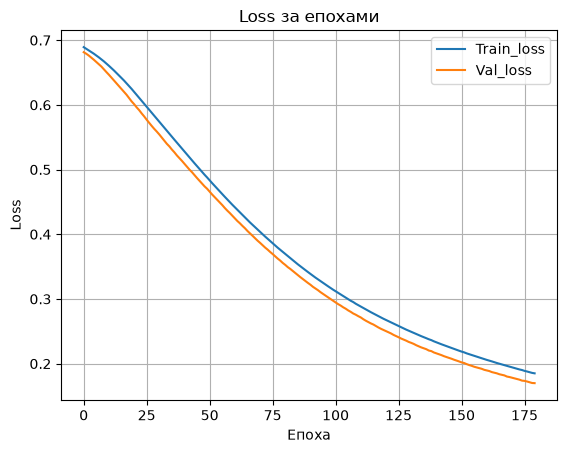

In [85]:
plt.plot(history.history["loss"], label="Train_loss")
plt.plot(history.history["val_loss"], label="Val_loss")
plt.title("Loss за епохами")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

Побудувати графік зміни точності (Accuracy) протягом навчання.

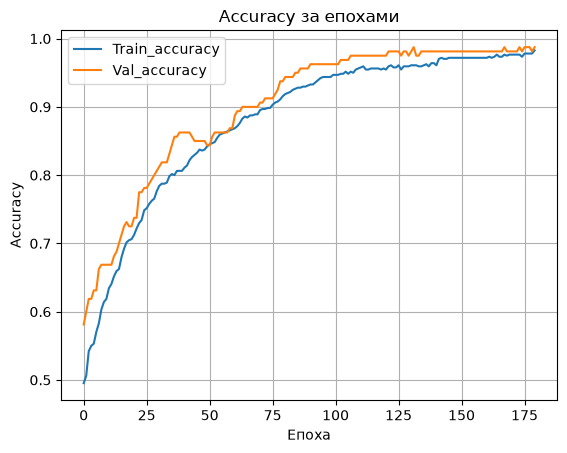

In [86]:
plt.plot(history.history["accuracy"], label="Train_accuracy")
plt.plot(history.history["val_accuracy"], label="Val_accuracy")
plt.title("Accuracy за епохами")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Оцінити точність навченої нейронної мережі на тестовій вибірці.

In [87]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Тестова точність: {accuracy * 100:.2f}%")
print(f"Тестова помилка: {loss:.4f}")

Тестова точність: 98.50%
Тестова помилка: 0.1758


Вивести передбачений клас для кожної точки.

In [88]:
probabilities = model.predict(X_test, verbose=0).flatten()
predictions = (probabilities >= 0.5).astype(int)

count_miss=0

for i in range(len(X_test)):
    x1, x2 = X_test[i]
    if predictions[i] != y_test[i]:
        count_miss +=1
    print(f"{i+1:3}. ({x1:.2f}, {x2:.2f}) - прогноз: {predictions[i]}, правильний: {y_test[i]}")

print("Не правильних прогнозів: ",count_miss)
    

  1. (0.32, 0.63) - прогноз: 0, правильний: 0
  2. (0.33, 0.67) - прогноз: 1, правильний: 0
  3. (0.82, 0.12) - прогноз: 0, правильний: 0
  4. (0.25, 0.16) - прогноз: 0, правильний: 0
  5. (0.33, 0.40) - прогноз: 0, правильний: 0
  6. (0.90, 0.42) - прогноз: 1, правильний: 1
  7. (0.12, 0.13) - прогноз: 0, правильний: 0
  8. (0.86, 0.84) - прогноз: 1, правильний: 1
  9. (0.98, 0.24) - прогноз: 1, правильний: 1
 10. (0.87, 0.91) - прогноз: 1, правильний: 1
 11. (0.56, 0.96) - прогноз: 1, правильний: 1
 12. (0.14, 0.49) - прогноз: 0, правильний: 0
 13. (0.78, 0.04) - прогноз: 0, правильний: 0
 14. (0.44, 0.15) - прогноз: 0, правильний: 0
 15. (0.59, 0.51) - прогноз: 1, правильний: 1
 16. (0.07, 0.01) - прогноз: 0, правильний: 0
 17. (0.70, 0.21) - прогноз: 0, правильний: 0
 18. (0.74, 0.48) - прогноз: 1, правильний: 1
 19. (0.35, 0.10) - прогноз: 0, правильний: 0
 20. (0.27, 0.38) - прогноз: 0, правильний: 0
 21. (0.78, 0.35) - прогноз: 1, правильний: 1
 22. (0.37, 0.63) - прогноз: 1, пр

Перевірити роботу мережі на 5 нових точках, які не використовувалися під час навчання.


In [89]:
new_points = np.array([
    [0.1, 0.2],
    [0.8, 0.6],
    [0.3, 0.4],
    [0.7, 0.9],
    [0.8, 0.1]
], dtype="float32")

# Реальні класи
real_classes = (new_points[:, 0] + new_points[:, 1] >= 1).astype(int)

# передбачений клас для кожної нової точки
new_probs = model.predict(new_points, verbose=0).flatten()
new_classes = (new_probs >= 0.5).astype(int)

for point, predicted,classes in zip(new_points, new_classes, real_classes):
    print(f"Точка {point} - клас {predicted} - справжній клас {classes}")

Точка [0.1 0.2] - клас 0 - справжній клас 0
Точка [0.8 0.6] - клас 1 - справжній клас 1
Точка [0.3 0.4] - клас 0 - справжній клас 0
Точка [0.7 0.9] - клас 1 - справжній клас 1
Точка [0.8 0.1] - клас 0 - справжній клас 0
